# Cycling infrastructure and shared e-scooter behaviour — results overview

Tel Aviv-Yafo, July 2023. ~1.36 M MDS trips and ~3.5 M vehicle status changes, provided by the
municipality. This notebook loads the outputs of the pipeline (`scripts/run_*.py`) and walks
through the three questions of the thesis:

1. **Route choice** — do riders go out of their way to use cycling infrastructure?
2. **Speed** — are they faster on it?
3. **Demand** — are scooters parked next to it picked up sooner?

All heavy lifting lives in the `sdes` package; every figure here is a function in `sdes.viz`.

In [1]:
import pandas as pd
from IPython.display import display

from sdes import viz
from sdes.config import Config
from sdes.geo import Layers
from sdes.io import read_geoparquet

cfg = Config.load()
P = cfg.paths.processed
layers = Layers(cfg)
viz.apply_style()

## 1. Data cleaning

Every rule is logged by `FilterReport`, so each funnel is auditable. The biggest cut is the
*low-resolution route* rule: a trip is kept only if no two consecutive GPS pings are more than
70 m apart (10 s ping interval × 25 km/h cap), otherwise its geometry can't be trusted for
route-level analysis.

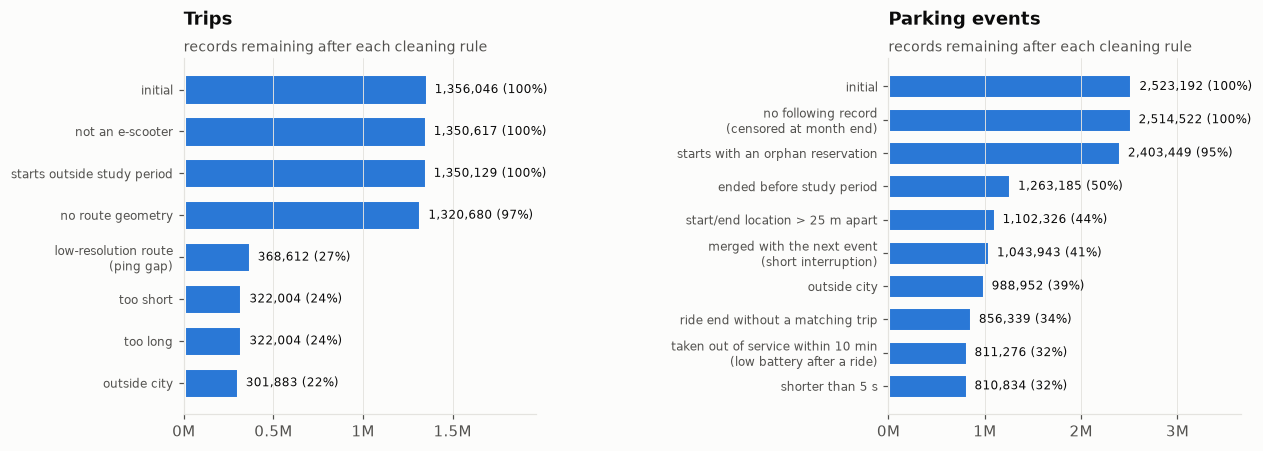

In [2]:
reports = {"Trips": pd.read_csv(P / "trips_clean_report.csv"),
           "Parking events": pd.read_csv(P / "parking_events_report.csv")}
viz.funnel(reports);

,length (km),duration (min),speed (km/h)
25%,1.0,5.3,10.0
50%,1.7,8.2,12.9
75%,2.6,12.5,15.7


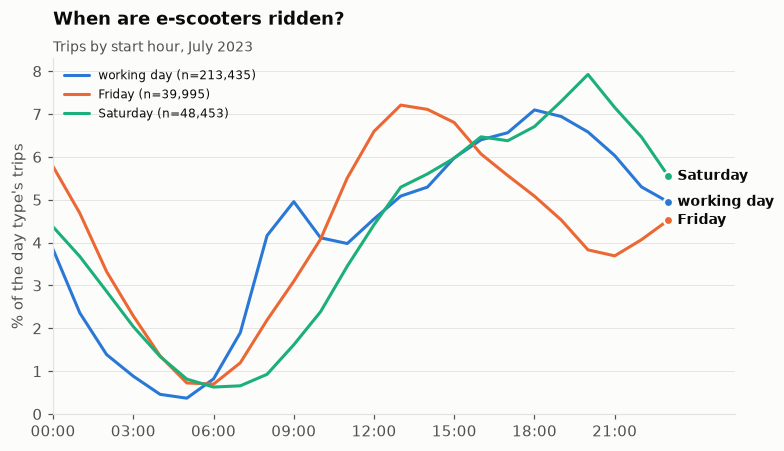

In [3]:
trips = pd.read_parquet(P / "trips_clean.parquet",
                        columns=["day_type", "start_hour", "length_m", "trip_duration",
                                 "speed_kmh"])
# quartiles, not mean/max: a handful of operator records carry a timestamp in trip_duration
summary = pd.DataFrame({"length (km)": trips["length_m"] / 1000,
                        "duration (min)": trips["trip_duration"] / 60,
                        "speed (km/h)": trips["speed_kmh"]})
display(summary.quantile([0.25, 0.5, 0.75]).rename(index=lambda q: f"{q:.0%}").round(1))
viz.hourly_trips(trips);

## 2. Route choice

Each trip is **map-matched** to the OpenStreetMap walk network (buffer the GPS track by 25 m,
keep edges ≥ 90 % inside the buffer, bridge disconnected pieces, take the shortest path through
that sub-network). The result is compared with the **shortest path** between the same two
nodes on the full network; both are intersected with a 25 m buffer around the municipal
cycling-infrastructure layer.

In [4]:
routes = read_geoparquet(P / "route_choice.parquet", columns=[
    "trip_id", "length_m", "matched_length_m", "sp_length_m", "infra_m", "sp_infra_m",
    "infra_pct", "sp_infra_pct", "detour_ratio", "reconnected", "matched", "shortest_path"])
display(pd.read_csv(P / "route_choice_report.csv"))
print(f"share on infrastructure: chosen {routes.infra_pct.mean():.1f}% "
      f"vs shortest path {routes.sp_infra_pct.mean():.1f}%; "
      f"mean detour {100 * (routes.detour_ratio.mean() - 1):.1f}%")

,step,removed,remaining
0,initial,0,301883
1,circular (start = end),26,301857
2,route/aerial ratio >= 2,29342,272515
3,could not be map-matched,0,272515
4,"short trip, |matched - GPS| > 100 m",8646,263869
5,"long trip, |matched - GPS| > 5%",64995,198874


share on infrastructure: chosen 57.8% vs shortest path 44.1%; mean detour 9.5%


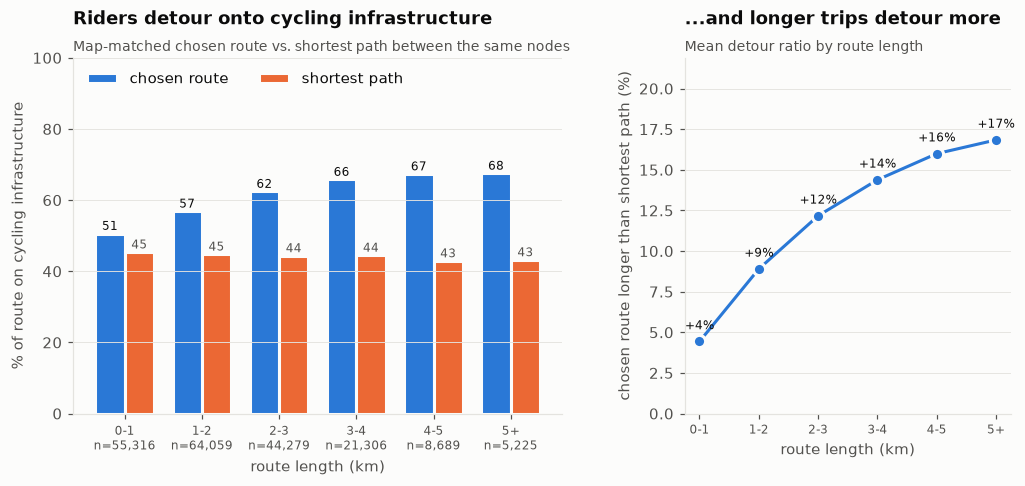

In [5]:
viz.infra_share_by_length(routes);

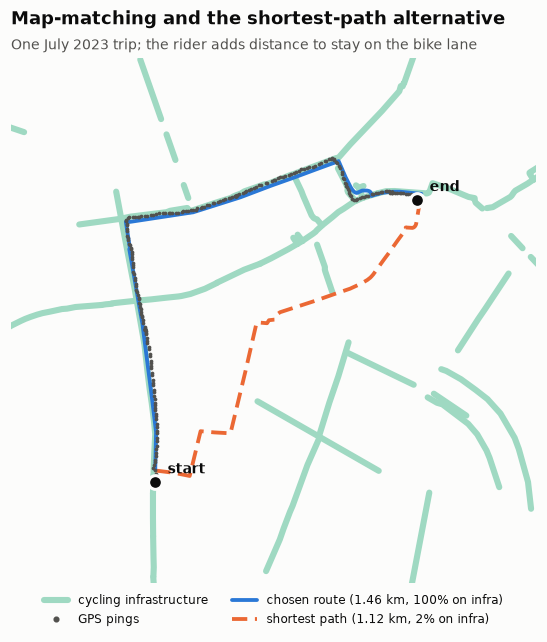

In [6]:
viz.route_example(viz.pick_example(routes), layers.bike_lanes);

## 3. Speed inside vs. outside cycling infrastructure

Each GPS route is cut into runs of pings inside / outside the infrastructure buffer, with the
transition placed midway between the last ping of one run and the first of the next. Runs
shorter than 80 m are treated as GPS noise and absorbed by their neighbour.

mean 12.85 km/h, median 13.07 km/h


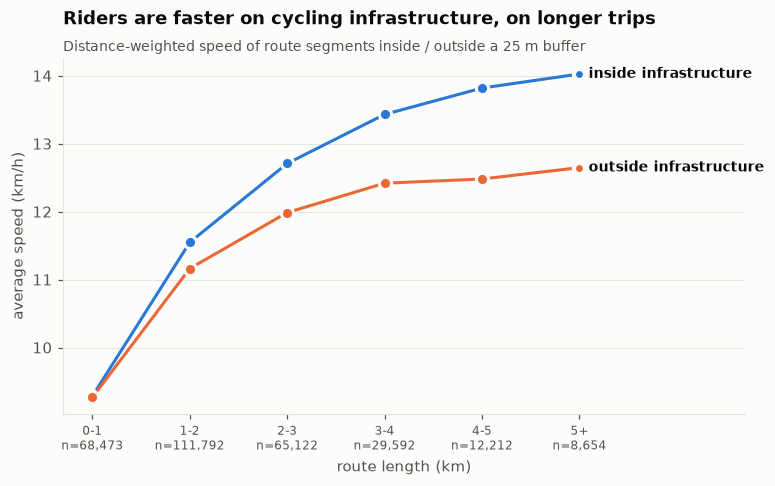

In [7]:
speed = pd.read_parquet(P / "speed.parquet")
print(f"mean {speed.moving_kmh.mean():.2f} km/h, median {speed.moving_kmh.median():.2f} km/h")
viz.speed_by_length(speed);

## 4. Parking demand

A *parking event* is the time a scooter stands ready to ride at one spot (built from the Status
Changes feed: consecutive `available`/`reserved` records within 25 m). For events that end in
a ride, a shorter parking time means higher demand at that location.

end_reason
on_trip            95.3
non_operational     2.4
removed             1.8
unknown             0.6
Name: % of events, dtype: float64

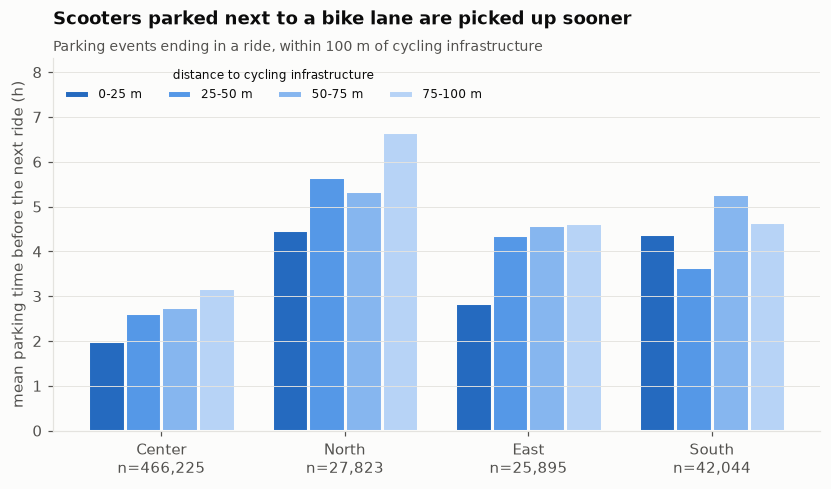

In [8]:
events = pd.read_parquet(P / "parking_events.parquet",
                         columns=["end_reason", "dist_to_infra_m", "area", "duration_s"])
display(events.end_reason.value_counts(normalize=True).mul(100).round(1).rename("% of events"))
viz.parking_by_distance(events);